# Imputación de faltantes y KNN para predecir promociones

Predicción de qué empleados serán promovidos (8,5 % de los casos) a partir de su departamento, formación, evaluación del año anterior, antigüedad y resultados de capacitación. El foco está en dos decisiones: cómo imputar los valores faltantes sin filtrar información del conjunto de prueba y cómo elegir el número de vecinos y la distancia de un KNN cuando la clase de interés es minoritaria.

Datos: [HR Analytics: Employee Promotion Data](https://www.kaggle.com/datasets/arashnic/hr-ana) (Kaggle), descargados con `kagglehub`. Solo se usa `train.csv`, el único archivo con la variable objetivo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             classification_report, PrecisionRecallDisplay)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

ruta = kagglehub.dataset_download('arashnic/hr-ana')
df = pd.read_csv(f'{ruta}/train.csv')
print(df.shape)
print(f"Promovidos: {df['is_promoted'].mean():.1%}")
faltantes = df.isna().mean().mul(100).round(2)
print(faltantes[faltantes > 0])

(54808, 13)
Promovidos: 8.5%
education               4.40
previous_year_rating    7.52
dtype: float64


## 1. Partición

Se separa un 20 % de prueba, estratificado, antes de cualquier otra decisión. Todo lo que se estima a partir de los datos (medias para imputar, escalas, vecinos) se ajusta solo con el entrenamiento.

In [2]:
X = df.drop(columns=['employee_id', 'is_promoted'])
y = df['is_promoted']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f'Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,}')

Entrenamiento: 43,846 | Prueba: 10,962


## 2. Imputación

- **`education`** (4,4 % faltante): se imputa con la categoría `Unknown`, para no confundir «no reportado» con una categoría real.
- **`previous_year_rating`** (7,5 % faltante): el desempeño pasado depende del área, así que se imputa con la media del departamento calculada en el entrenamiento; si un departamento no aparece, con la mediana global.

El imputador por departamento es un transformador de scikit-learn, de modo que dentro de la validación cruzada se recalcula en cada pliegue sin ver el pliegue de validación.

In [3]:
class ImputarPorGrupo(BaseEstimator, TransformerMixin):
    """Imputa una columna numérica con la media de su grupo (estimada en el ajuste)."""

    def __init__(self, columna, grupo):
        self.columna = columna
        self.grupo = grupo

    def fit(self, X, y=None):
        self.medias_ = X.groupby(self.grupo)[self.columna].mean()
        self.global_ = X[self.columna].median()
        return self

    def transform(self, X):
        X = X.copy()
        relleno = X[self.grupo].map(self.medias_).fillna(self.global_)
        X[self.columna] = X[self.columna].fillna(relleno)
        return X


categoricas = ['department', 'region', 'education', 'gender', 'recruitment_channel']
numericas = [c for c in X.columns if c not in categoricas]

preproceso = ColumnTransformer([
    ('num', StandardScaler(), numericas),
    ('cat', Pipeline([('imputar', SimpleImputer(strategy='constant', fill_value='Unknown')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categoricas),
])

def modelo_knn(k, metrica):
    return Pipeline([
        ('rating', ImputarPorGrupo('previous_year_rating', 'department')),
        ('preproceso', preproceso),
        ('smote', SMOTE(random_state=42)),
        ('knn', KNeighborsClassifier(n_neighbors=k, metric=metrica)),
    ])

imputador = ImputarPorGrupo('previous_year_rating', 'department').fit(X_train)
print('Media de previous_year_rating por departamento (entrenamiento):')
print(imputador.medias_.round(2))

Media de previous_year_rating por departamento (entrenamiento):
department
Analytics            3.55
Finance              3.51
HR                   3.49
Legal                3.43
Operations           3.64
Procurement          3.30
R&D                  3.58
Sales & Marketing    3.07
Technology           3.16
Name: previous_year_rating, dtype: float64


## 3. Selección de K y distancia

SMOTE genera ejemplos sintéticos de la clase minoritaria, y va dentro del pipeline para que solo se aplique al entrenamiento de cada pliegue. Como KNN da probabilidades (la fracción de vecinos promovidos), los modelos se comparan por el área bajo la curva precisión-recall (AUC-PR), que no depende de un umbral y es la métrica adecuada con una clase del 8,5 %. Como referencia, un clasificador al azar tiene AUC-PR igual a la proporción de positivos.

,distancia,K,AUC-PR,desv.
0,euclidean,5,0.172,0.007
1,euclidean,15,0.221,0.006
2,euclidean,31,0.255,0.001
3,euclidean,61,0.290,0.003
4,euclidean,121,0.327,0.005
5,euclidean,201,0.338,0.007
6,manhattan,5,0.176,0.006
7,manhattan,15,0.236,0.007
8,manhattan,31,0.277,0.007
9,manhattan,61,0.302,0.007


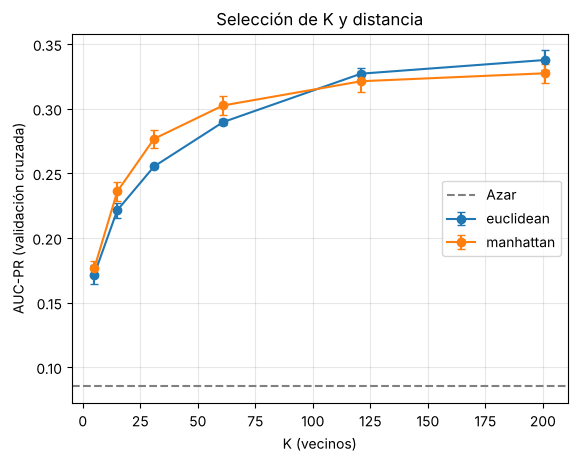

In [4]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
filas = []
for metrica in ('euclidean', 'manhattan'):
    for k in (5, 15, 31, 61, 121, 201):
        auc_pr = cross_val_score(modelo_knn(k, metrica), X_train, y_train, cv=cv,
                                 scoring='average_precision', n_jobs=-1)
        filas.append({'distancia': metrica, 'K': k, 'AUC-PR': auc_pr.mean(), 'desv.': auc_pr.std()})
seleccion = pd.DataFrame(filas)
display(seleccion.round(3))

for metrica, grupo in seleccion.groupby('distancia'):
    plt.errorbar(grupo['K'], grupo['AUC-PR'], yerr=grupo['desv.'], marker='o', capsize=3, label=metrica)
plt.axhline(y_train.mean(), color='gray', linestyle='--', label='Azar')
plt.xlabel('K (vecinos)')
plt.ylabel('AUC-PR (validación cruzada)')
plt.title('Selección de K y distancia')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4. Evaluación en prueba

Modelo elegido: K = 201, distancia euclidean


AUC-PR: 0.334 (azar: 0.085)
AUC-ROC: 0.761


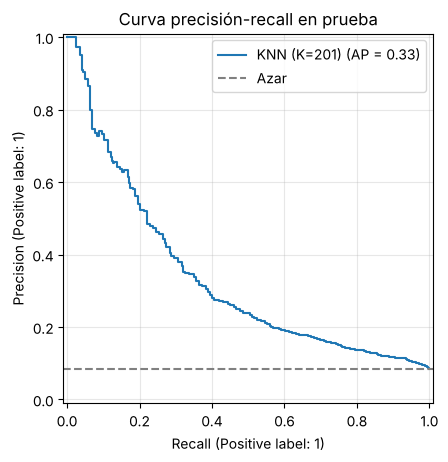

In [5]:
mejor = seleccion.loc[seleccion['AUC-PR'].idxmax()]
print(f"Modelo elegido: K = {mejor['K']}, distancia {mejor['distancia']}")
modelo = modelo_knn(int(mejor['K']), mejor['distancia']).fit(X_train, y_train)
proba = modelo.predict_proba(X_test)[:, 1]
print(f'AUC-PR: {average_precision_score(y_test, proba):.3f} (azar: {y_test.mean():.3f})')
print(f'AUC-ROC: {roc_auc_score(y_test, proba):.3f}')

PrecisionRecallDisplay.from_predictions(y_test, proba, name=f"KNN (K={mejor['K']})")
plt.axhline(y_test.mean(), color='gray', linestyle='--', label='Azar')
plt.legend()
plt.title('Curva precisión-recall en prueba')
plt.grid(alpha=0.3)
plt.show()

La curva muestra el compromiso disponible: subir el recall (encontrar más promovidos) cuesta precisión. El umbral depende de lo que se quiera priorizar; como ejemplo, el umbral habitual de 0,5 y, solo como ilustración (se calcula sobre la misma prueba), el que maximiza el F1 de la clase promovida:

In [6]:
precision, recall, umbrales = precision_recall_curve(y_test, proba)
f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
idx = np.argmax(f1)
for nombre, u in [('Umbral 0,5', 0.5), (f'Umbral {umbrales[idx]:.2f} (máximo F1)', umbrales[idx])]:
    print(nombre)
    print(classification_report(y_test, (proba >= u).astype(int), digits=3,
                                target_names=['No promovido', 'Promovido']))

Umbral 0,5
              precision    recall  f1-score   support

No promovido      0.965     0.559     0.708     10028
   Promovido      0.142     0.782     0.240       934

    accuracy                          0.578     10962
   macro avg      0.553     0.671     0.474     10962
weighted avg      0.895     0.578     0.668     10962

Umbral 0.76 (máximo F1)
              precision    recall  f1-score   support

No promovido      0.939     0.938     0.939     10028
   Promovido      0.345     0.349     0.347       934

    accuracy                          0.888     10962
   macro avg      0.642     0.644     0.643     10962
weighted avg      0.889     0.888     0.888     10962



**Análisis**

- Imputar con la media del departamento tiene sentido: el rating promedio va de 3,07 (Sales & Marketing) a 3,64 (Operations), una diferencia que una mediana global borraría.
- El AUC-PR mejora de forma sostenida al aumentar K, con las dos distancias, y se aplana a partir de unos 120 vecinos. Con una clase minoritaria y ruidosa, pocos vecinos dan probabilidades muy inestables; muchos vecinos las suavizan. Euclidiana y Manhattan quedan muy cerca.
- En prueba, el modelo elegido (K = 201, euclidiana) obtiene AUC-PR de 0,334, casi cuatro veces el azar (0,085), y AUC-ROC de 0,76.
- El umbral cambia por completo la lectura: con 0,5 (efecto de SMOTE, que equilibra las clases al entrenar) encuentra el 78 % de los promovidos, pero solo el 14 % de sus alertas son correctas. Con un umbral más alto, precisión y recall quedan alrededor del 35 %.
- KNN separa poco a los promovidos con estas variables: aun en el mejor punto, dos de cada tres alertas son falsas. El valor del ejercicio está en el procedimiento (imputación sin fuga, remuestreo dentro de la validación y una métrica que no depende del umbral) más que en el modelo.